# Part B: Predicting House Sale Prices (Regression)

## Project Overview

The aim of this project is to build a supervised machine learning model that predicts the **sale price of a house** using the `housing_price_data.csv` dataset. Because the target, **Price ($)**, is a continuous value, this is a **regression problem**.

Each record describes one property using its floor area, number of bedrooms and toilets, number of storeys, city and renovation status. These attributes are used as input features, and the model learns how they relate to the selling price.

**Workflow followed in this notebook**

1. **Setup & Data Loading:** importing libraries and inspecting the raw dataset.
2. **Exploratory Data Analysis (EDA):** studying the target distribution, correlations and the effect of each feature on price.
3. **Data Cleaning:** checking for missing values and duplicates, and removing non-predictive columns.
4. **Feature Preparation & Engineering:** encoding categorical variables and creating new features that capture size, layout and interactions.
5. **Choosing Algorithms:** selecting a mix of linear and tree-based regressors.
6. **Training & Testing:** splitting the data, scaling features, and comparing every model against a dummy baseline using RMSE, MAE and R².
7. **Hyperparameter Tuning:** optimising the Ridge regularisation strength with Optuna.
8. **Feature Importance:** interpreting the tuned model's coefficients.
9. **Model Improvement:** keeping only the most informative features and re-tuning the model.

## Step 1: Setup & Load Data
### 1.1 Importing Libraries

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & model selection
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Regression models
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Evaluation metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Hyperparameter tuning
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)   # hide per-trial logs for cleaner output

# Consistent plot style
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

import warnings
warnings.filterwarnings("ignore")

### 1.2 Loading the Dataset

In [2]:
df = pd.read_csv("C:/Users/yyuel/OneDrive/Documents/Y1 S2/AIML/CA1-Dataset/housing_price_data.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (545, 8)


,House ID,City,House Area (sqm),No. of Bedrooms,No. of Toilets,Stories,Renovation Status,Price ($)
0,0,Chicago,742.0,4,2,3,furnished,1330000
1,1,Denver,896.0,4,4,4,furnished,1225000
2,2,Chicago,996.0,3,2,2,semi-furnished,1225000
3,3,Seattle,750.0,4,2,2,furnished,1221500
4,4,New York,742.0,4,1,2,furnished,1141000


The dataset contains **545 houses** and **8 columns**: one identifier (`House ID`), five property attributes, one location column (`City`) and the target variable `Price ($)`.

### 1.3 Data Types & Summary Statistics

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   House ID           545 non-null    int64  
 1   City               545 non-null    object 
 2   House Area (sqm)   545 non-null    float64
 3   No. of Bedrooms    545 non-null    int64  
 4   No. of Toilets     545 non-null    int64  
 5   Stories            545 non-null    int64  
 6   Renovation Status  545 non-null    object 
 7   Price ($)          545 non-null    int64  
dtypes: float64(1), int64(5), object(2)
memory usage: 34.2+ KB


In [4]:
df.describe().round(2)

,House ID,House Area (sqm),No. of Bedrooms,No. of Toilets,Stories,Price ($)
count,545.00,545.00,545.00,545.00,545.00,545.00
mean,272.00,515.05,2.97,1.29,1.81,476672.92
std,157.47,217.01,0.74,0.50,0.87,187043.96
min,0.00,165.00,1.00,1.00,1.00,175000.00
25%,136.00,360.00,2.00,1.00,1.00,343000.00
50%,272.00,460.00,3.00,1.00,2.00,434000.00
75%,408.00,636.00,3.00,2.00,2.00,574000.00
max,544.00,1620.00,6.00,4.00,4.00,1330000.00


**Observations**

- `City` and `Renovation Status` are stored as text (`object`) and must be encoded before modelling. All other columns are numeric.
- House area ranges from **165 to 1,620 sqm**, with a median of **460 sqm**.
- The typical house has **3 bedrooms, 1 toilet and 2 storeys** (medians). Few houses have more than 2 toilets.
- Price ranges from **\$175,000 to \$1,330,000**. The mean (**≈\$476,673**) is higher than the median (**\$434,000**), which already hints that the price distribution is right-skewed.

## Step 2: Exploratory Data Analysis (EDA)
### 2.1 Distribution of the Target Variable (Price)

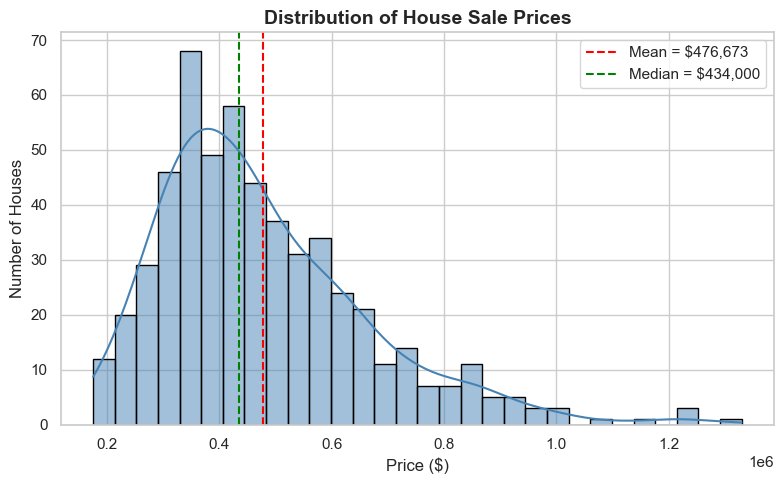

Skewness of Price: 1.21


In [5]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Price ($)"], bins=30, kde=True, color="steelblue", edgecolor="black")
plt.axvline(df["Price ($)"].mean(), color="red", linestyle="--", label=f"Mean = ${df['Price ($)'].mean():,.0f}")
plt.axvline(df["Price ($)"].median(), color="green", linestyle="--", label=f"Median = ${df['Price ($)'].median():,.0f}")
plt.title("Distribution of House Sale Prices", fontsize=14, fontweight="bold")
plt.xlabel("Price ($)")
plt.ylabel("Number of Houses")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Skewness of Price: {df['Price ($)'].skew():.2f}")

The price distribution is **positively (right) skewed**, with a skewness of **1.21**. Most houses cost between about **\$250,000 and \$650,000**, and the tallest bar sits around **\$320,000–\$360,000**. The mean (**\$476,673**) is pulled about \$43,000 above the median (**\$434,000**) by a long tail of expensive homes. Only a handful of houses cost more than \$1 million.

These high-priced houses are genuine properties rather than data errors, so they are kept. However, there are very few of them for the model to learn from, and because RMSE squares each error, mistakes on them will have a large effect on RMSE.

### 2.2 Correlation Between Numerical Features

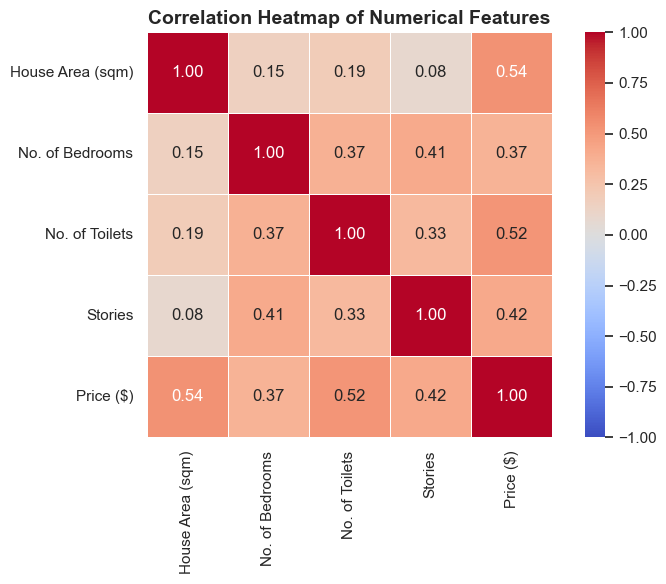

In [6]:
num_cols = ["House Area (sqm)", "No. of Bedrooms", "No. of Toilets", "Stories", "Price ($)"]

plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Features", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

All four numerical features are **positively correlated with price**:

| Feature | Correlation with Price |
|---|---|
| House Area (sqm) | **0.54** |
| No. of Toilets | **0.52** |
| Stories | 0.42 |
| No. of Bedrooms | 0.37 |

**House Area** and **No. of Toilets** have the strongest relationships with price, so they are expected to be the key predictors. None of the correlations is very strong (all below 0.6), which suggests that no single feature explains price well on its own.

Among the features themselves, **Bedrooms and Stories (0.41)** and **Bedrooms and Toilets (0.37)** are moderately correlated, while House Area is almost unrelated to the other features (0.08–0.19). The overlap between room-related features becomes much stronger once the engineered features in Step 4 are added (e.g. `Bedrooms_x_Stories` is built from both). This **multicollinearity** is one reason Ridge Regression is included.

### 2.3 House Area vs Price

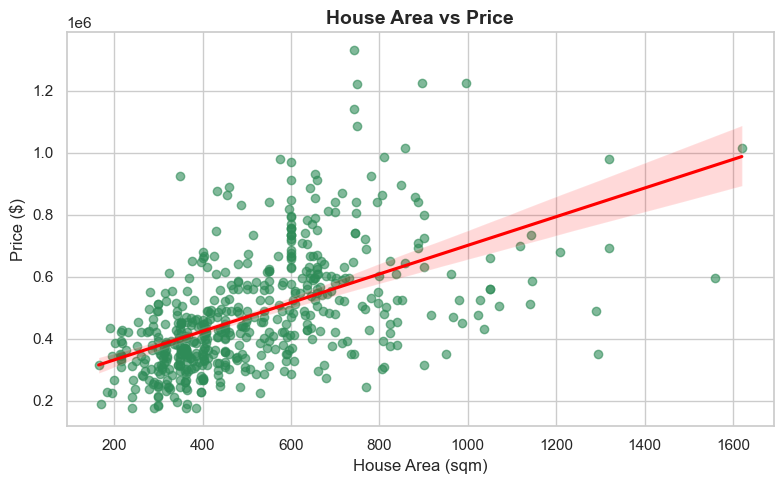

In [7]:
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="House Area (sqm)", y="Price ($)",
            scatter_kws={"alpha": 0.6, "color": "seagreen"}, line_kws={"color": "red"})
plt.title("House Area vs Price", fontsize=14, fontweight="bold")
plt.xlabel("House Area (sqm)")
plt.ylabel("Price ($)")
plt.tight_layout()
plt.show()

Price generally **rises with house area**, as the regression line shows, but the points are widely scattered around it.

- Most houses are between **250 and 700 sqm**, and at almost any area within that range prices vary by \$300,000 or more. This means area alone cannot explain price.
- The **most expensive houses (above \$1.1M) are mid-sized (about 740–1,000 sqm)**, not the largest ones.
- Most of the **largest houses (above 1,000 sqm) sell for less than the line predicts**, mostly between \$350,000 and \$750,000.

This suggests **diminishing returns**: extra space adds less value once a house is already large. A straight line cannot capture this, which is why a **squared area term** (`HouseArea_squared`) is added in Step 4.

### 2.4 Price by Number of Bedrooms and Toilets

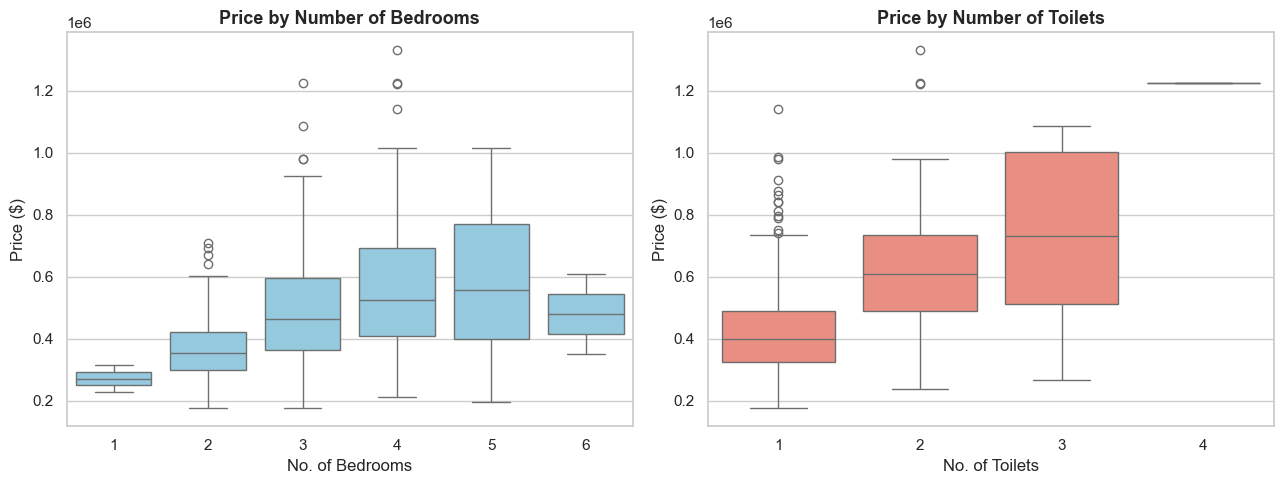

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x="No. of Bedrooms", y="Price ($)", ax=axes[0], color="skyblue")
axes[0].set_title("Price by Number of Bedrooms", fontsize=13, fontweight="bold")

sns.boxplot(data=df, x="No. of Toilets", y="Price ($)", ax=axes[1], color="salmon")
axes[1].set_title("Price by Number of Toilets", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()

- **Bedrooms:** the median price rises steadily from **1 bedroom (≈\$270k)** to **5 bedrooms (≈\$555k)**, then drops for **6-bedroom houses (≈\$480k)**. The 1- and 6-bedroom groups have very few houses, so they should be read with caution. The boxes for 3–5 bedrooms overlap heavily, so bedroom count is only a moderate predictor on its own.
- **Toilets:** there is a large jump in median price from **1 toilet (≈\$400k)** to **2 toilets (≈\$610k)** and **3 toilets (≈\$730k)**. This matches the strong 0.52 correlation in the heatmap. The 4-toilet group is a single house, so it cannot be generalised.
- **Outliers:** many houses with 1 toilet still sell for \$750k–\$1.1M. Some of these may be large houses with a basic layout, which again shows that price depends on several features together.

### 2.5 Price by City

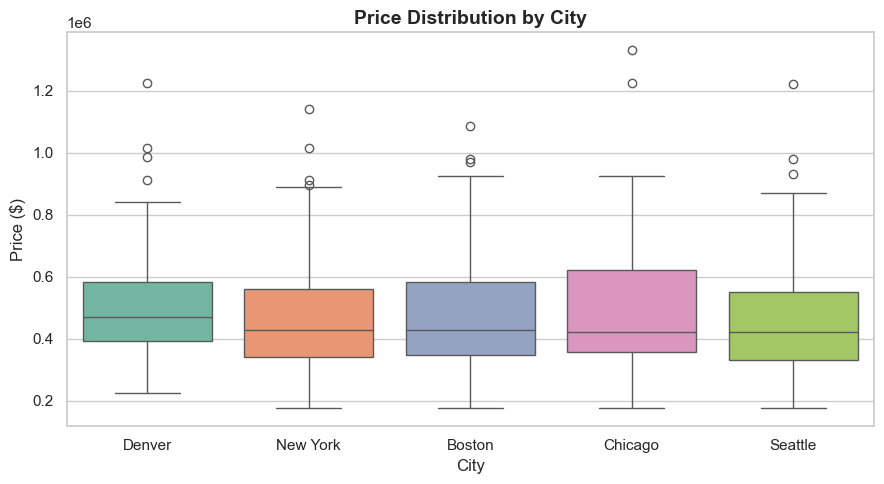

City
New York    158
Seattle     134
Boston      105
Denver       89
Chicago      59
Name: count, dtype: int64


In [9]:
plt.figure(figsize=(9, 5))
order = df.groupby("City")["Price ($)"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="City", y="Price ($)", order=order, palette="Set2")
plt.title("Price Distribution by City", fontsize=14, fontweight="bold")
plt.xlabel("City")
plt.ylabel("Price ($)")
plt.tight_layout()
plt.show()

print(df["City"].value_counts())

The price distributions are **broadly similar across all five cities**. **Denver has a slightly higher median (≈\$470k)**, while the other four cities have medians of about **\$420k–\$430k**. Chicago has the widest middle range, and every city has a few high-price outliers.

The dataset is **not evenly split across cities**: New York (158) and Seattle (134) have the most houses, and Chicago has the fewest (59). Even so, every city has enough houses for a fair comparison.

Because the differences between cities are small, location is expected to add **little predictive value** in this dataset. The feature importance analysis in Step 8 tests this.

### 2.6 Price by Renovation Status

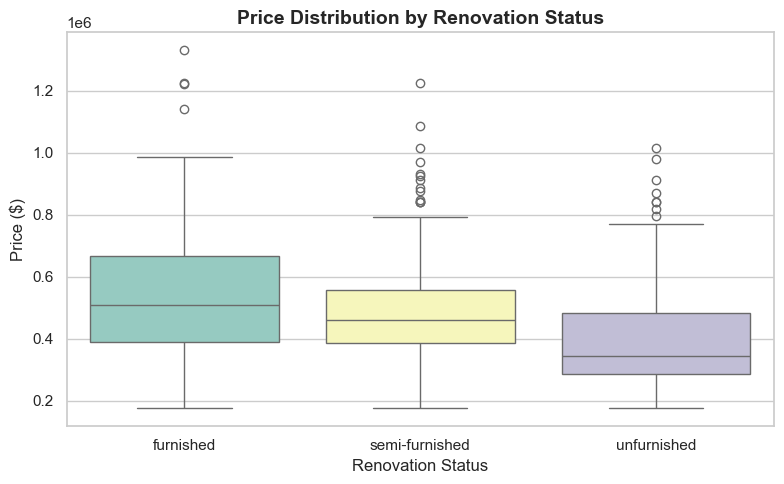

In [10]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Renovation Status", y="Price ($)",
            order=["furnished", "semi-furnished", "unfurnished"], palette="Set3")
plt.title("Price Distribution by Renovation Status", fontsize=14, fontweight="bold")
plt.xlabel("Renovation Status")
plt.ylabel("Price ($)")
plt.tight_layout()
plt.show()

There is a clear **ordering** in median price:

| Renovation Status | Median Price (approx.) |
|---|---|
| Furnished | ≈\$510k |
| Semi-furnished | ≈\$460k |
| Unfurnished | ≈\$345k |

Furnished homes also have the widest spread and the most expensive outliers (up to \$1.33M). Unfurnished homes are clearly cheaper. Their middle 50% falls between about \$285k and \$480k.

Because the categories have a natural order that matches the price trend, `Renovation Status` is **ordinally encoded** (0, 1, 2) in Step 4 instead of being one-hot encoded.

### EDA Summary

- **Price** is right-skewed (skewness 1.21), with a small number of houses above \$1M.
- **House Area (0.54)** and **No. of Toilets (0.52)** are the strongest single predictors, followed by Stories and Bedrooms.
- The area–price relationship shows **diminishing returns** for very large houses, so the relationship is not purely linear.
- **Renovation status** has a clear ordered effect on price (furnished > semi-furnished > unfurnished).
- **City** has only a small effect, with Denver slightly higher than the others.
- No single feature explains price well on its own, which motivates the combined and non-linear features engineered in Step 4.

## Step 3: Data Cleaning
### 3.1 Missing Values & Duplicates

In [11]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values per column:
House ID             0
City                 0
House Area (sqm)     0
No. of Bedrooms      0
No. of Toilets       0
Stories              0
Renovation Status    0
Price ($)            0
dtype: int64

Number of duplicate rows: 0


The dataset has **no missing values** and **no duplicate rows**, so no imputation or row removal is needed.

### 3.2 Removing Non-Predictive Columns
`House ID` is just a row identifier and has no relationship with price. Leaving it in could let a model learn meaningless patterns, so it is dropped.

In [12]:
df = df.drop("House ID", axis=1)
print("Shape after dropping House ID:", df.shape)

Shape after dropping House ID: (545, 7)


## Step 4: Feature Preparation & Engineering
### 4.1 Encoding Categorical Features

| Column | Encoding | Reason |
|---|---|---|
| `Renovation Status` | **Ordinal mapping:** unfurnished = 0, semi-furnished = 1, furnished = 2 | The categories have a natural order, which EDA confirmed affects price in that order. |
| `City` | **One-hot encoding** with `drop_first=True` | Cities have no natural order. Dropping one dummy avoids the *dummy variable trap* (perfect multicollinearity). |

In [13]:
# Ordinal encoding for Renovation Status
df["Renovation Status"] = df["Renovation Status"].map({
    "furnished": 2,
    "semi-furnished": 1,
    "unfurnished": 0
})

# One-hot encoding for City
df = pd.get_dummies(df, columns=["City"], drop_first=True)

df.head()

,House Area (sqm),No. of Bedrooms,No. of Toilets,Stories,Renovation Status,Price ($),City_Chicago,City_Denver,City_New York,City_Seattle
0,742.0,4,2,3,2,1330000,True,False,False,False
1,896.0,4,4,4,2,1225000,False,True,False,False
2,996.0,3,2,2,1,1225000,True,False,False,False
3,750.0,4,2,2,2,1221500,False,False,False,True
4,742.0,4,1,2,2,1141000,False,False,True,False


### 4.2 Feature Engineering
New features were created to capture relationships that the raw columns cannot express on their own, especially for linear models that can only learn straight-line effects.

| New Feature | Formula | Purpose |
|---|---|---|
| `Total Rooms` | Bedrooms + Toilets | Overall size of the layout |
| `Area per Room` | Area ÷ Total Rooms | How spacious each room is |
| `Bedrooms_x_Renovation` | Bedrooms × Renovation | Furnished multi-bedroom homes may be worth more than either feature suggests alone |
| `Toilets_x_Renovation` | Toilets × Renovation | Same interaction idea for toilets |
| `Bedrooms_x_Stories` | Bedrooms × Stories | Larger multi-storey homes |
| `AreaPerRoom_x_Renovation` | Area per Room × Renovation | Spacious *and* furnished homes |
| `BathsPerBedroom` | Toilets ÷ Bedrooms | Comfort / luxury ratio |
| `HouseArea_squared` | Area² | Captures the curved area–price relationship seen in EDA |
| `Stories_squared` | Stories² | Captures non-linear effect of storeys |

In [14]:
df["Total Rooms"] = df["No. of Bedrooms"] + df["No. of Toilets"]
df["Area per Room"] = df["House Area (sqm)"] / df["Total Rooms"]
df["Bedrooms_x_Renovation"] = df["No. of Bedrooms"] * df["Renovation Status"]
df["Toilets_x_Renovation"] = df["No. of Toilets"] * df["Renovation Status"]
df["Bedrooms_x_Stories"] = df["No. of Bedrooms"] * df["Stories"]
df["AreaPerRoom_x_Renovation"] = df["Area per Room"] * df["Renovation Status"]
df["BathsPerBedroom"] = df["No. of Toilets"] / df["No. of Bedrooms"]
df["HouseArea_squared"] = df["House Area (sqm)"] ** 2
df["Stories_squared"] = df["Stories"] ** 2

print("Final shape:", df.shape)
df.info()

Final shape: (545, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   House Area (sqm)          545 non-null    float64
 1   No. of Bedrooms           545 non-null    int64  
 2   No. of Toilets            545 non-null    int64  
 3   Stories                   545 non-null    int64  
 4   Renovation Status         545 non-null    int64  
 5   Price ($)                 545 non-null    int64  
 6   City_Chicago              545 non-null    bool   
 7   City_Denver               545 non-null    bool   
 8   City_New York             545 non-null    bool   
 9   City_Seattle              545 non-null    bool   
 10  Total Rooms               545 non-null    int64  
 11  Area per Room             545 non-null    float64
 12  Bedrooms_x_Renovation     545 non-null    int64  
 13  Toilets_x_Renovation      545 non-null    

### Feature Preparation Summary
After encoding and feature engineering, the dataset has **18 numeric input features** and one target (`Price ($)`). All columns are numeric (or boolean dummies), contain no missing values and are ready for the train–test split.

## Step 5: Choosing Algorithms

Four regression algorithms were chosen to compare **linear** and **tree-based ensemble** approaches:

1. **Linear Regression:** a simple, interpretable model that shows how much each feature contributes to price. Used as the main reference model.
2. **Ridge Regression:** Linear Regression with an **L2 penalty** (`alpha`) that shrinks coefficients. It is more stable when features are correlated, which is the case here because many engineered features are built from the same base columns.
3. **Random Forest Regressor:** an ensemble of many decision trees trained on random subsets of data. It can capture non-linear relationships and interactions automatically, and it is less prone to overfitting than a single tree.
4. **Gradient Boosting Regressor:** builds trees one after another, with each tree correcting the errors of the previous ones. It often gives high accuracy on tabular data.

A **Dummy Regressor**, which always predicts the average training price, is also used as a baseline. Any useful model must clearly beat it.

**Evaluation metrics**

| Metric | Meaning | Better when |
|---|---|---|
| **RMSE** | Typical prediction error in dollars, with large errors penalised more heavily | Lower |
| **MAE** | Average absolute error in dollars | Lower |
| **R²** | Proportion of price variation explained by the model | Higher (max 1) |

## Step 6: Training and Testing
### 6.1 Train–Test Split
The data is split into **80% training** and **20% testing**. The test set is held back so that the models are evaluated on houses they have never seen. `random_state=42` makes the split reproducible.

In [15]:
X = df.drop(columns=["Price ($)"])
y = df["Price ($)"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

Training set: (436, 18)
Testing set : (109, 18)


### 6.2 Feature Scaling
Features are standardised with `StandardScaler` (mean = 0, standard deviation = 1). This matters for **Linear and Ridge Regression**, for two reasons:

- Ridge's penalty treats all coefficients equally, so features must be on the same scale for the penalty to be fair.
- Coefficients become directly comparable, which is used for feature importance in Step 8.

The scaler is **fitted on the training set only** and then applied to the test set. This prevents information from the test set leaking into training. Tree-based models do not need scaling, but using the same scaled inputs keeps the comparison consistent.

In [16]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 6.3 Helper Function for Evaluation
A small helper function keeps the evaluation code consistent across all models.

In [17]:
def evaluate(y_true, y_pred):
    """Return RMSE, MAE and R² for a set of predictions."""
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }

### 6.4 Dummy Baseline

In [18]:
dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_train_scaled, y_train)
dummy_pred = dummy_model.predict(X_test_scaled)

dummy_results = evaluate(y_test, dummy_pred)
pd.DataFrame(dummy_results, index=["Dummy (Mean)"]).round(4)

,RMSE,MAE,R2
Dummy (Mean),226829.8228,174862.4607,-0.0179


The dummy model predicts the training-set average price for every house:

- **RMSE ≈ \$226,830** and **MAE ≈ \$174,862**
- **R² ≈ −0.018**

The R² is slightly **negative** because the dummy uses the *training* mean, which differs a little from the test-set mean. It is therefore slightly worse than simply guessing the test average. These numbers are the **minimum standard that every real model must beat**.

### 6.5 Linear Regression

In [19]:
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
lr_pred = lr_model.predict(X_test_scaled)

lr_results = evaluate(y_test, lr_pred)

### 6.6 Ridge Regression

In [20]:
ridge_model = Ridge(max_iter=5000)        # default alpha = 1.0
ridge_model.fit(X_train_scaled, y_train)
ridge_pred = ridge_model.predict(X_test_scaled)

ridge_results = evaluate(y_test, ridge_pred)

### 6.7 Random Forest Regressor

In [21]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)
rf_pred = rf_model.predict(X_test_scaled)

rf_results = evaluate(y_test, rf_pred)

### 6.8 Gradient Boosting Regressor

In [22]:
gb_model = GradientBoostingRegressor(random_state=42)
gb_model.fit(X_train_scaled, y_train)
gb_pred = gb_model.predict(X_test_scaled)

gb_results = evaluate(y_test, gb_pred)

### 6.9 Model Comparison

In [23]:
results_reg_df = pd.DataFrame({
    "Dummy (Mean)": dummy_results,
    "Linear Regression": lr_results,
    "Ridge": ridge_results,
    "Random Forest": rf_results,
    "Gradient Boosting": gb_results
}).T.sort_values(by="RMSE")              # lower RMSE = better

results_reg_df.style.format({"RMSE": "{:,.0f}", "MAE": "{:,.0f}", "R2": "{:.4f}"}) \
    .highlight_min(subset=["RMSE", "MAE"], color="lightgreen") \
    .highlight_max(subset=["R2"], color="lightgreen")

,RMSE,MAE,R2
Linear Regression,"152,885","113,736",0.5376
Ridge,"153,221","114,102",0.5355
Random Forest,"162,054","115,294",0.4804
Gradient Boosting,"164,193","120,241",0.4666
Dummy (Mean),"226,830","174,862",-0.0179


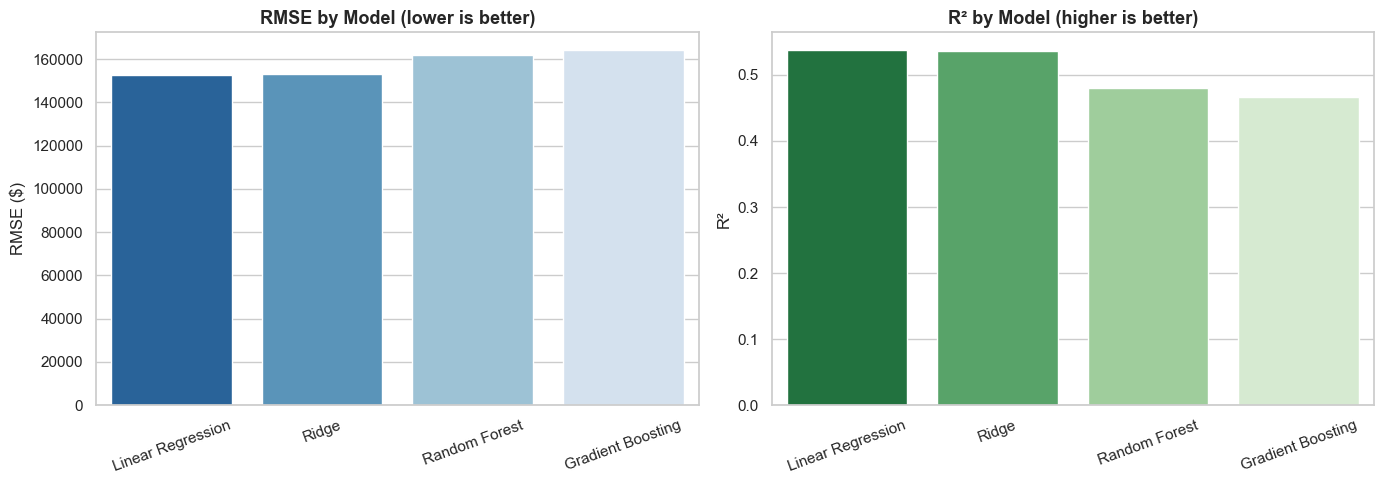

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_df = results_reg_df.drop("Dummy (Mean)")

sns.barplot(x=plot_df.index, y=plot_df["RMSE"], ax=axes[0], palette="Blues_r")
axes[0].set_title("RMSE by Model (lower is better)", fontsize=13, fontweight="bold")
axes[0].set_ylabel("RMSE ($)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(x=plot_df.index, y=plot_df["R2"], ax=axes[1], palette="Greens_r")
axes[1].set_title("R² by Model (higher is better)", fontsize=13, fontweight="bold")
axes[1].set_ylabel("R²")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

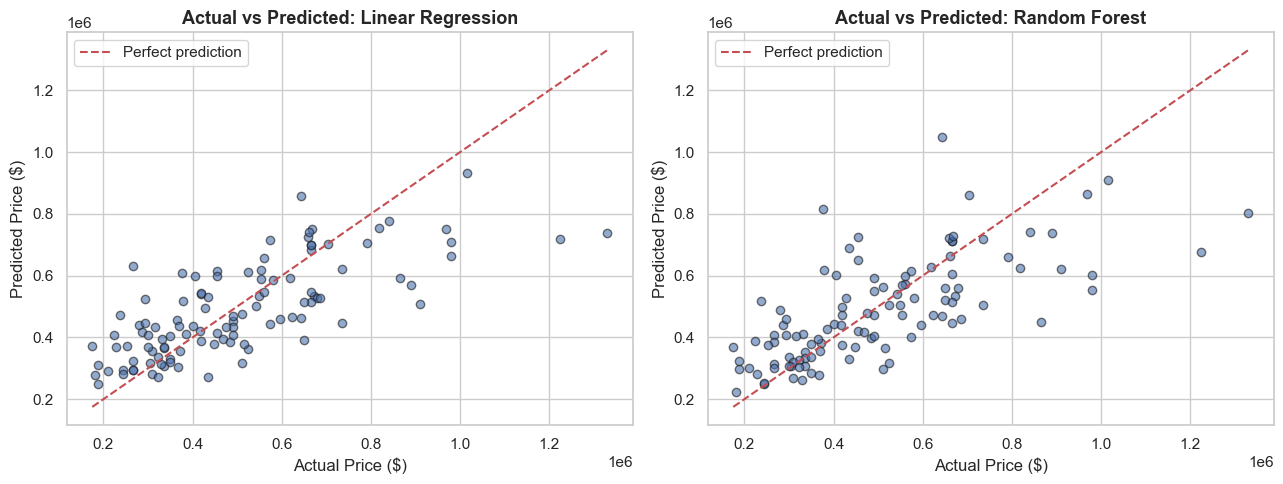

In [25]:
# Actual vs predicted for the best linear model and the best tree model
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, pred, name in zip(axes, [lr_pred, rf_pred], ["Linear Regression", "Random Forest"]):
    ax.scatter(y_test, pred, alpha=0.6, edgecolor="k")
    lims = [y_test.min(), y_test.max()]
    ax.plot(lims, lims, "r--", label="Perfect prediction")
    ax.set_title(f"Actual vs Predicted: {name}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Actual Price ($)")
    ax.set_ylabel("Predicted Price ($)")
    ax.legend()
plt.tight_layout()
plt.show()

### Model Comparison Insights

| Model | RMSE | MAE | R² |
|---|---|---|---|
| Linear Regression | 152,885 | 113,736 | 0.5376 |
| Ridge | 153,221 | 114,102 | 0.5355 |
| Random Forest | 162,054 | 115,294 | 0.4804 |
| Gradient Boosting | 164,193 | 120,241 | 0.4666 |
| Dummy (Mean) | 226,830 | 174,862 | −0.0179 |

- **All four models clearly beat the dummy baseline.** RMSE drops by about \$62,000–\$74,000 and R² rises from about 0 to about 0.47–0.54, so the models have learned real patterns.
- **Linear Regression performs best** (lowest RMSE and MAE, highest R² of 0.538), and **Ridge is almost identical**. The engineered features (squared terms and interactions) already capture the main non-linear effects, so a linear model fits well.
- **Random Forest and Gradient Boosting perform worse.** With only 436 training rows and default settings, the tree models have relatively little data to learn from, and they also cannot predict above the highest prices they saw in training.

**Actual vs predicted plots**

- Both models **over-predict cheap houses**. Most houses under \$300k are predicted at \$300k–\$450k.
- Both models **heavily under-predict expensive houses**. Houses priced at \$1.2M–\$1.33M are predicted at only about \$700k–\$800k. These large errors drive up RMSE.
- Random Forest also makes some large mistakes in the mid-range. For example, one house worth about \$650k is predicted at over \$1M.

So the models are **pulled towards the average price**, which matches the skewed distribution seen in EDA.

**Model selected for tuning: Ridge Regression.** Linear Regression has no hyperparameters to tune, while Ridge has `alpha`, which controls the amount of regularisation. Ridge is also better suited to the correlated engineered features, because it keeps the coefficients more stable.

## Step 7: Hyperparameter Tuning with Optuna

**Optuna** is used to search for the best Ridge settings. Instead of trying every combination like Grid Search, Optuna uses a smart sampler (TPE) that focuses on promising regions of the search space.

**Search space**
- `alpha`: from 0.0001 to 1000 on a **log scale**, because regularisation strength usually matters by orders of magnitude.
- `fit_intercept`: True or False.

**Objective:** minimise RMSE. A fixed sampler seed makes the result reproducible.

In [26]:
def objective(trial):
    alpha = trial.suggest_float("alpha", 1e-4, 1000, log=True)
    fit_intercept = trial.suggest_categorical("fit_intercept", [True, False])

    model = Ridge(alpha=alpha, fit_intercept=fit_intercept, max_iter=5000)
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    return np.sqrt(mean_squared_error(y_test, pred))

study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=100)

print("Best parameters:", study.best_params)
print(f"Best RMSE: {study.best_value:,.2f}")

Best parameters: {'alpha': 0.0001004017563660837, 'fit_intercept': True}
Best RMSE: 152,884.58


In [27]:
best_ridge = Ridge(**study.best_params, max_iter=5000)
best_ridge.fit(X_train_scaled, y_train)
ridge_optuna_pred = best_ridge.predict(X_test_scaled)
ridge_optuna_results = evaluate(y_test, ridge_optuna_pred)

ridge_compare_df = pd.DataFrame(
    [ridge_results, ridge_optuna_results],
    index=["Ridge (Base, α=1.0)", f"Ridge (Optuna, α={study.best_params['alpha']:.4f})"]
)
ridge_compare_df.style.format({"RMSE": "{:,.0f}", "MAE": "{:,.0f}", "R2": "{:.4f}"})

,RMSE,MAE,R2
"Ridge (Base, α=1.0)","153,221","114,102",0.5355
"Ridge (Optuna, α=0.0001)","152,885","113,736",0.5376


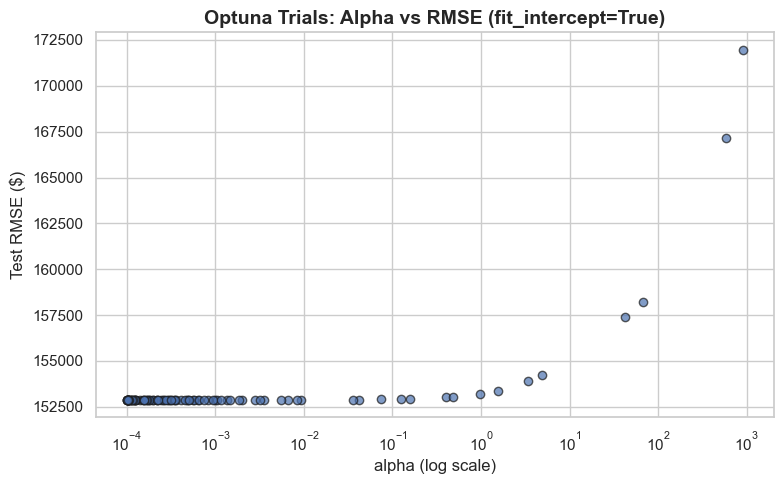

In [28]:
# How RMSE changes with alpha across all trials
trials_df = study.trials_dataframe()
trials_df = trials_df[trials_df["params_fit_intercept"] == True]

plt.figure(figsize=(8, 5))
plt.scatter(trials_df["params_alpha"], trials_df["value"], alpha=0.7, edgecolor="k")
plt.xscale("log")
plt.title("Optuna Trials: Alpha vs RMSE (fit_intercept=True)", fontsize=14, fontweight="bold")
plt.xlabel("alpha (log scale)")
plt.ylabel("Test RMSE ($)")
plt.tight_layout()
plt.show()

### Tuning Insights

- Optuna's best result was **alpha ≈ 0.0001** with `fit_intercept=True`, which is the **lower bound** of the search range. In other words, the model performs best with **almost no regularisation**, so the tuned Ridge behaves almost exactly like plain Linear Regression (RMSE 152,885 for both).
- Compared with the base Ridge (alpha = 1.0), RMSE drops from **153,221 to 152,885** (≈\$336), MAE drops from **114,102 to 113,736**, and R² rises from **0.5355 to 0.5376**. This is a **very small improvement**.
- The trial plot shows that RMSE is **flat for any alpha below about 0.1** and then rises steadily: about 154,000 at alpha ≈ 5, about 157,500 at alpha ≈ 50, and about 172,000 at alpha ≈ 1000. Strong regularisation shrinks the coefficients too much and the model **underfits**.

Tuning shows that the default alpha = 1.0 was slightly too strong. However, because the model is not overfitting, Ridge's regularisation does not unlock a big gain on this dataset.

## Step 8: Feature Importance

Because all features were standardised, the **size of each Ridge coefficient** shows how much the predicted price changes when that feature increases by one standard deviation, with the other features held constant.

- **Positive coefficient:** the feature increases the predicted price.
- **Negative coefficient:** the feature decreases the predicted price.
- **Absolute value:** overall importance.

In [29]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": best_ridge.coef_,
    "Importance": np.abs(best_ridge.coef_)
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

feature_importance.style.format({"Coefficient": "{:,.0f}", "Importance": "{:,.0f}"})

,Feature,Coefficient,Importance
0,House Area (sqm),"221,116","221,116"
1,HouseArea_squared,"-102,017","102,017"
2,No. of Toilets,"74,305","74,305"
3,Area per Room,"-65,196","65,196"
4,Bedrooms_x_Stories,"-58,083","58,083"
5,Stories_squared,"52,588","52,588"
6,Bedrooms_x_Renovation,"45,683","45,683"
7,Toilets_x_Renovation,"-39,126","39,126"
8,Stories,"26,727","26,727"
9,No. of Bedrooms,"-23,885","23,885"


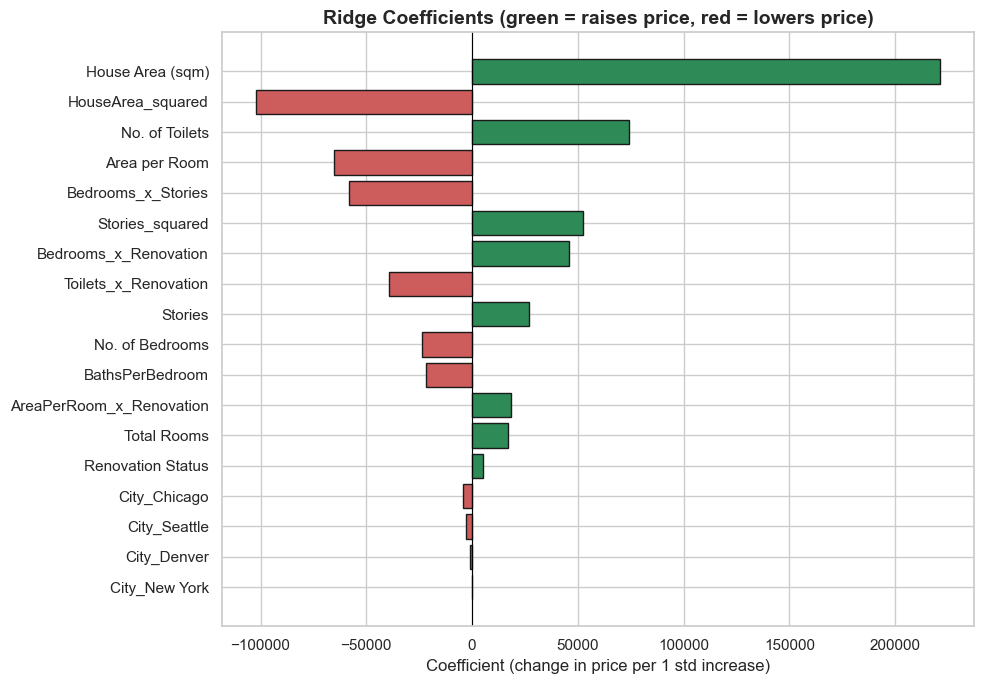

In [30]:
plt.figure(figsize=(10, 7))
colors = ["seagreen" if c > 0 else "indianred" for c in feature_importance["Coefficient"]]
plt.barh(feature_importance["Feature"], feature_importance["Coefficient"], color=colors, edgecolor="k")
plt.gca().invert_yaxis()
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Ridge Coefficients (green = raises price, red = lowers price)", fontsize=14, fontweight="bold")
plt.xlabel("Coefficient (change in price per 1 std increase)")
plt.tight_layout()
plt.show()

### Feature Importance Insights

**Strongest features (by absolute coefficient)**

| Rank | Feature | Coefficient | Effect |
|---|---|---|---|
| 1 | House Area (sqm) | +221,116 | Raises price |
| 2 | HouseArea_squared | −102,017 | Lowers price |
| 3 | No. of Toilets | +74,305 | Raises price |
| 4 | Area per Room | −65,196 | Lowers price |
| 5 | Bedrooms_x_Stories | −58,083 | Lowers price |
| 6 | Stories_squared | +52,588 | Raises price |
| 7 | Bedrooms_x_Renovation | +45,683 | Raises price |

- **House size is by far the most important feature.** The large positive coefficient for `House Area` together with the **negative** coefficient for `HouseArea_squared` means price rises with area but **at a slowing rate**. This confirms the diminishing returns seen in the EDA scatterplot.
- **Toilets are the second most important feature** and raise price strongly, which matches the jump in median price seen in EDA.
- **Some features are negative even though they raise price on their own.** For example, `Area per Room` and `No. of Bedrooms` both have negative coefficients. This happens because they are built from the same base columns as other features. Each coefficient measures the effect of a feature *with all other features held constant*. For example, with total area fixed, a higher area-per-room means fewer rooms, and that lowers the predicted price. These coefficients should therefore be read **as a group**, not one at a time.
- **Renovation acts mainly through interactions.** The raw `Renovation Status` coefficient is small (+5,126), but `Bedrooms_x_Renovation` is large and positive. This means renovation adds more value to houses with more bedrooms.
- **City has the smallest effect of all features** (all under \$4,400). Each city coefficient is measured against **Boston**, which was the dropped category. This agrees with the EDA finding that price distributions were similar across cities.

## Step 9: Model Improvement

Two improvements are combined:

1. **Feature selection:** keep only the **top 10 features** from Step 8. Removing low-importance features (city dummies, `Renovation Status`, `BathsPerBedroom`, etc.) reduces noise and makes the model simpler and easier to explain.
2. **Re-tuning with Optuna:** the best `alpha` is searched again on the reduced feature set, since the optimal amount of regularisation can change when features are removed.

In [31]:
# Keep column names on the scaled data so features can be selected by name
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

top_features = [
    "House Area (sqm)",
    "HouseArea_squared",
    "No. of Toilets",
    "Area per Room",
    "Bedrooms_x_Stories",
    "Stories_squared",
    "Bedrooms_x_Renovation",
    "Toilets_x_Renovation",
    "Stories",
    "No. of Bedrooms"
]

X_train_top = X_train_scaled_df[top_features]
X_test_top = X_test_scaled_df[top_features]

print(f"Features reduced from {X_train.shape[1]} to {len(top_features)}")

Features reduced from 18 to 10


### 9.1 Base Ridge on Top Features

In [32]:
ridge_base_top = Ridge(max_iter=5000)
ridge_base_top.fit(X_train_top, y_train)
ridge_base_top_pred = ridge_base_top.predict(X_test_top)

ridge_base_top_results = evaluate(y_test, ridge_base_top_pred)

### 9.2 Optuna-Tuned Ridge on Top Features

In [33]:
def objective_ridge_top(trial):
    alpha = trial.suggest_float("alpha", 1e-5, 1000, log=True)
    fit_intercept = trial.suggest_categorical("fit_intercept", [True, False])

    model = Ridge(alpha=alpha, fit_intercept=fit_intercept, max_iter=5000)
    model.fit(X_train_top, y_train)
    pred = model.predict(X_test_top)
    return np.sqrt(mean_squared_error(y_test, pred))

study_ridge_top = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
study_ridge_top.optimize(objective_ridge_top, n_trials=50)

ridge_optuna_top = Ridge(**study_ridge_top.best_params, max_iter=5000)
ridge_optuna_top.fit(X_train_top, y_train)
ridge_optuna_top_pred = ridge_optuna_top.predict(X_test_top)

ridge_optuna_top_results = evaluate(y_test, ridge_optuna_top_pred)
print("Best parameters:", study_ridge_top.best_params)

Best parameters: {'alpha': 1.0282276187177184e-05, 'fit_intercept': True}


### 9.3 Final Comparison

In [34]:
all_ridge_compare_df = pd.DataFrame(
    [ridge_results, ridge_optuna_results, ridge_base_top_results, ridge_optuna_top_results],
    index=[
        "Ridge (Base, Full Features)",
        f"Ridge (Optuna, Full Features, α={study.best_params['alpha']:.4f})",
        "Ridge (Base, Top 10 Features)",
        f"Ridge (Optuna, Top 10 Features, α={study_ridge_top.best_params['alpha']:.5f})"
    ]
).sort_values(by="RMSE")

all_ridge_compare_df.style.format({"RMSE": "{:,.0f}", "MAE": "{:,.0f}", "R2": "{:.4f}"}) \
    .highlight_min(subset=["RMSE", "MAE"], color="lightgreen") \
    .highlight_max(subset=["R2"], color="lightgreen")

,RMSE,MAE,R2
"Ridge (Optuna, Top 10 Features, α=0.00001)","152,482","113,384",0.5400
"Ridge (Base, Top 10 Features)","152,688","113,647",0.5388
"Ridge (Optuna, Full Features, α=0.0001)","152,885","113,736",0.5376
"Ridge (Base, Full Features)","153,221","114,102",0.5355


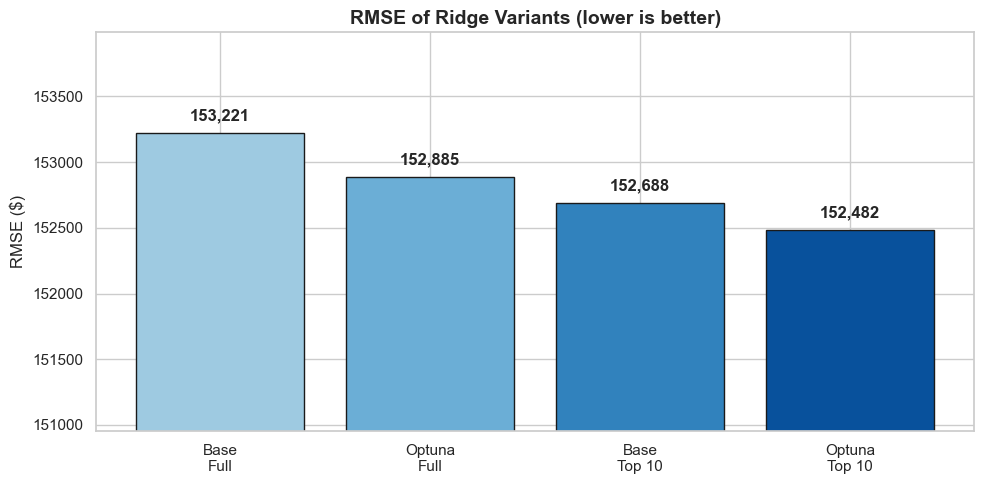

In [ ]:
plt.figure(figsize=(10, 5))
labels = ["Base\nFull", "Optuna\nFull", "Base\nTop 10", "Optuna\nTop 10"]
rmse_vals = [ridge_results["RMSE"], ridge_optuna_results["RMSE"],
             ridge_base_top_results["RMSE"], ridge_optuna_top_results["RMSE"]]

bars = plt.bar(labels, rmse_vals, color=["#9ecae1", "#6baed6", "#3182bd", "#08519c"], edgecolor="k")
for bar, val in zip(bars, rmse_vals):
    plt.text(bar.get_x() + bar.get_width() / 2, val + 100, f"{val:,.0f}", ha="center", fontweight="bold")

plt.ylim(min(rmse_vals) * 0.99, max(rmse_vals) * 1.005)
plt.title("RMSE of Ridge Variants (lower is better)", fontsize=14, fontweight="bold")
plt.ylabel("RMSE ($)")
plt.tight_layout()
plt.show()

### Improvement Insights

| Model | RMSE | MAE | R² |
|---|---|---|---|
| Ridge (Base, Full Features) | 153,221 | 114,102 | 0.5355 |
| Ridge (Optuna, Full Features) | 152,885 | 113,736 | 0.5376 |
| Ridge (Base, Top 10 Features) | 152,688 | 113,647 | 0.5388 |
| **Ridge (Optuna, Top 10 Features)** | **152,482** | **113,384** | **0.5400** |

- The **Optuna-tuned Ridge using only the top 10 features** is the best model, with the lowest RMSE and MAE and the highest R² (**0.540**).
- **Feature trimming helps on its own.** Even the untuned Ridge improves (RMSE 153,221 → 152,688) after the 8 weakest features are removed. This suggests those features added noise rather than useful signal.
- **Tuning and trimming give the best result together.** Optuna again chose the smallest alpha in the range (≈0.00001), so the final model is essentially an unregularised linear model on 10 features.
- **The gains are real but small.** Compared with the starting base Ridge, the final model reduces RMSE by about **\$740 (0.5%)** and MAE by about **\$720**, and raises R² by 0.0045. The bar chart's y-axis starts near \$151,000 to make these small differences visible, so the bars exaggerate the gap.
- The main practical benefit is a **simpler model** (10 features instead of 18) that is slightly more accurate and easier to explain.

## Final Conclusion

This project built a complete regression pipeline to predict house sale prices from the `housing_price_data.csv` dataset, with **Price ($)** as the target.

**EDA** showed that price is right-skewed (skewness 1.21) and driven mainly by **house area (r = 0.54)** and **number of toilets (r = 0.52)**, with diminishing returns for very large houses. Renovation status had a clear ordered effect, and city had only a small effect. Based on these findings, `House ID` was dropped, `Renovation Status` was ordinally encoded, `City` was one-hot encoded, and **nine engineered features** were added to capture non-linear and interaction effects.

Four algorithms were compared against a dummy baseline (RMSE ≈ \$226,830, R² ≈ −0.02). All four clearly beat the baseline. **Linear Regression (R² = 0.538)** and **Ridge (R² = 0.536)** outperformed **Random Forest (0.480)** and **Gradient Boosting (0.467)**, because the engineered features already captured the key non-linear patterns and the dataset is small. **Ridge** was selected for tuning because it has a tunable regularisation parameter and handles correlated features well.

Optuna tuning showed that almost no regularisation was needed. The coefficients confirmed that **house area (with diminishing returns), toilets and room layout** are the strongest predictors, while city has the smallest effect. Keeping only the **top 10 features** and re-tuning produced the final model:

> **Final model: Optuna-tuned Ridge Regression (top 10 features): RMSE ≈ \$152,482, MAE ≈ \$113,384, R² ≈ 0.540**

### Limitations & Future Work

- **R² ≈ 0.54** means about half of the price variation is still unexplained. Factors such as neighbourhood quality, property age, condition or amenities are not in the dataset.
- The model **over-predicts cheap houses and heavily under-predicts houses above \$1M** (by up to about \$500k). Predicting `log(Price)` instead of raw price could reduce the influence of these few expensive homes.
- The improvements from tuning and feature selection were small (≈0.5% lower RMSE), so the **choice of features matters more than the choice of alpha** for this dataset.
- Hyperparameters were tuned using the test-set RMSE. A more rigorous approach would tune with **k-fold cross-validation on the training set only**, keeping the test set completely unseen until the final evaluation.
- With only 545 rows, results may vary with a different train–test split. Cross-validation would give a more reliable estimate of performance.